# 3. Análisis de la variable objetivo (2.1)

**Objetivo:** número de sismos M ≥ 2,5 en la celda durante el mes siguiente.

Todo el capítulo usa **solo el entrenamiento**, es decir, los meses objetivo hasta noviembre de 2020.
Las conclusiones de aquí deciden la métrica, la transformación del objetivo y la validación.

In [1]:
# Localiza la raíz del libro (la carpeta con _config.yml) para poder importar los módulos de src/
import sys
from pathlib import Path
raiz = Path.cwd().resolve()
while not (raiz / "_config.yml").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
# Librerías de análisis y módulos propios: configuración, datos, EDA, evaluación y utilidades del libro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import config as cfg, datos, eda, evaluacion as ev
from src.libro import md, tabla, mostrar_plotly
from src.eda import es, p_fmt
# Estilo común de los gráficos, semilla global (SEMILLA = 42) y formato de las tablas
eda.configurar_graficos()
cfg.fijar_semillas()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

In [2]:
# Distribución del objetivo (sismos por celda-mes) en el entrenamiento: frecuencias y acumulado
ev_, X, info, tr, gp, te = datos.panel_completo()
P = datos.panel_dataframe(X, info, tr)
y = P["y"].to_numpy()
frec = (pd.Series(y).value_counts().sort_index().rename_axis("sismos_en_el_mes").to_frame("celdas_mes"))
frec["%"] = 100 * frec.celdas_mes / len(y)
frec["% acumulado"] = frec["%"].cumsum()
desc = pd.DataFrame({
    "n": [len(y)], "media": [y.mean()], "varianza": [y.var()], "índice de dispersión (var/media)": [y.var() / y.mean()],
    "mediana": [np.median(y)], "p90": [np.percentile(y, 90)], "p99": [np.percentile(y, 99)], "máx": [y.max()],
    "% ceros": [100 * np.mean(y == 0)], "asimetría": [stats.skew(y)], "curtosis": [stats.kurtosis(y)],
    "asimetría log1p": [stats.skew(np.log1p(y))],
})
eda.guardar_tabla(desc, "objetivo_resumen.csv")
eda.guardar_tabla(frec.reset_index(), "objetivo_frecuencias.csv")
display(desc.round(2))
frec.head(12).round(2)

,n,media,varianza,índice de dispersión (var/media),mediana,p90,p99,máx,% ceros,asimetría,curtosis,asimetría log1p
0,30970,0.81,32.36,40.06,0.0,1.0,7.0,148.0,76.3,13.15,190.65,3.95


,celdas_mes,%,% acumulado
sismos_en_el_mes,,,
0.0,23629,76.30,76.30
1.0,5086,16.42,92.72
2.0,1262,4.07,96.79
3.0,364,1.18,97.97
4.0,182,0.59,98.56
5.0,89,0.29,98.84
6.0,47,0.15,99.00
7.0,27,0.09,99.08
8.0,19,0.06,99.14


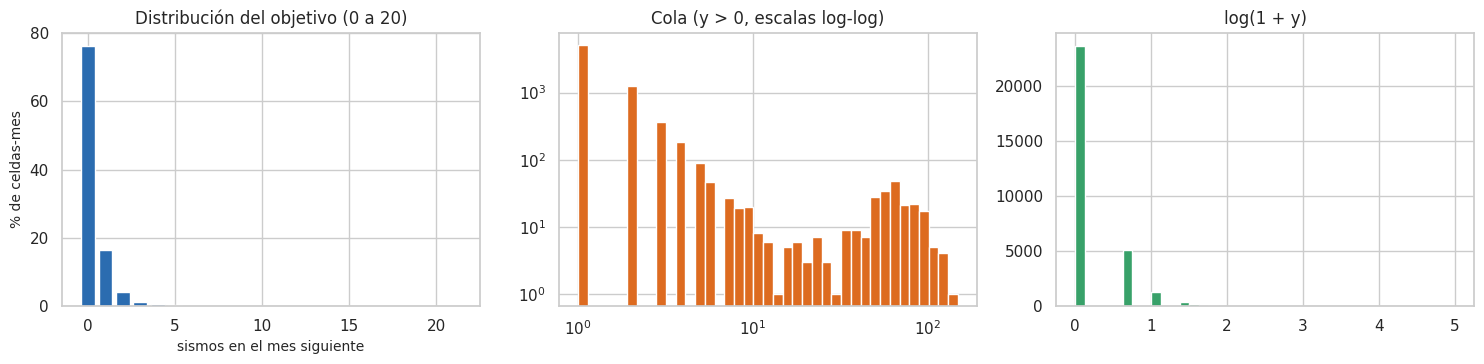

In [3]:
# Gráficos del objetivo: zona 0–20, cola en escala log-log y log(1 + y)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].bar(frec.index[:21], frec["%"].iloc[:21], color="#2b6cb0")
axes[0].set_title("Distribución del objetivo (0 a 20)"); axes[0].set_xlabel("sismos en el mes siguiente"); axes[0].set_ylabel("% de celdas-mes")
axes[1].hist(y[y > 0], bins=np.logspace(0, np.log10(y.max() + 1), 40), color="#dd6b20")
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_title("Cola (y > 0, escalas log-log)")
axes[2].hist(np.log1p(y), bins=40, color="#38a169"); axes[2].set_title("log(1 + y)")
plt.tight_layout(); eda.guardar_figura(fig, "03_distribucion_objetivo.png"); plt.show()

## ¿Poisson, binomial negativa o inflada en ceros?

Se compara la proporción de ceros observada con la que predicen una Poisson y una binomial negativa
de la misma media. Primero se hace globalmente y después **dentro de cada celda**, porque la mezcla
de celdas activas e inactivas por sí sola ya produce sobredispersión.

In [4]:
# Exceso de ceros y sobredispersión: ceros observados frente a Poisson y binomial negativa, global y por celda
mu, v = y.mean(), y.var()
r_nb = mu ** 2 / max(v - mu, 1e-9)
global_ = {"observado": np.mean(y == 0), "Poisson": np.exp(-mu), "Binomial negativa": (r_nb / (r_nb + mu)) ** r_nb}
por_celda = P.groupby("celda").y.agg(["mean", "var", lambda s: np.mean(s == 0)]).rename(columns={"<lambda_0>": "ceros"})
por_celda["ceros_Poisson"] = np.exp(-por_celda["mean"])
por_celda["dispersion"] = por_celda["var"] / por_celda["mean"].replace(0, np.nan)
ceros = pd.DataFrame({"proporción de ceros": global_}).T
eda.guardar_tabla(por_celda.reset_index(), "objetivo_por_celda.csv")
display(ceros.round(3))
md(f"""**Interpretación.**
- **Global.** Una Poisson con la media del entrenamiento ({es(mu, 2)}) esperaría {es(global_['Poisson'], 1, pct=True)} de ceros; se observan
  {es(global_['observado'], 1, pct=True)}. El índice de dispersión var/media = {es(v / mu, 1)} (1 en una Poisson) indica **sobredispersión
  extrema**. Una binomial negativa con la misma media y varianza se pasa al otro extremo ({es(global_['Binomial negativa'], 1, pct=True)} de ceros):
  **ninguna distribución única** describe bien la mezcla de celdas tan distintas.
- **Dentro de cada celda.** La sobredispersión es **moderada en la celda típica** (índice var/media mediano de
  {es(por_celda.dispersion.median(), 1)}), pero fuerte en las celdas activas: en {es((por_celda.dispersion > 1.5).mean(), 0, pct=True)} de las celdas pasa de 1,5.
  La mediana del exceso de ceros sobre una Poisson con la media de la propia celda es de solo {es((por_celda.ceros - por_celda.ceros_Poisson).median(), 1, pct=True)}.
  Conclusión: la sobredispersión global se debe **sobre todo a la heterogeneidad entre celdas** y, en las celdas activas,
  al agrupamiento temporal.
- **Por qué importa.** El modelo debe distinguir las celdas (heterogeneidad) y, en las activas, capturar que los sismos llegan
  **en grupos** (réplicas, enjambres). Esto es coherente con los modelos de
  autoexcitación tipo ETAS (Ogata, 1988), en los que un sismo aumenta la probabilidad de otros cercanos en tiempo y espacio.""")

,observado,Poisson,Binomial negativa
proporción de ceros,0.763,0.446,0.927


**Interpretación.**
- **Global.** Una Poisson con la media del entrenamiento (0,81) esperaría 44,6 % de ceros; se observan
  76,3 %. El índice de dispersión var/media = 40,1 (1 en una Poisson) indica **sobredispersión
  extrema**. Una binomial negativa con la misma media y varianza se pasa al otro extremo (92,7 % de ceros):
  **ninguna distribución única** describe bien la mezcla de celdas tan distintas.
- **Dentro de cada celda.** La sobredispersión es **moderada en la celda típica** (índice var/media mediano de
  1,2), pero fuerte en las celdas activas: en 28 % de las celdas pasa de 1,5.
  La mediana del exceso de ceros sobre una Poisson con la media de la propia celda es de solo 1,6 %.
  Conclusión: la sobredispersión global se debe **sobre todo a la heterogeneidad entre celdas** y, en las celdas activas,
  al agrupamiento temporal.
- **Por qué importa.** El modelo debe distinguir las celdas (heterogeneidad) y, en las activas, capturar que los sismos llegan
  **en grupos** (réplicas, enjambres). Esto es coherente con los modelos de
  autoexcitación tipo ETAS (Ogata, 1988), en los que un sismo aumenta la probabilidad de otros cercanos en tiempo y espacio.

## Valores extremos: los enjambres

In [5]:
# Las 10 celdas-mes con más sismos y la magnitud máxima de ese mes
top = P.nlargest(10, "y")[["fecha_obj", "celda", "lat", "lon", "y", "n_1m", "n_12m"]]
mmax = ev_.groupby(["celda", "mes"]).mag.max()
top["mag_max_en_el_mes"] = [mmax.get((c, m), np.nan) for c, m in zip(top.celda, P.loc[top.index, "mes_obj"])]
top["fecha_obj"] = top.fecha_obj.dt.strftime("%Y-%m")
eda.guardar_tabla(top, "objetivo_extremos.csv")
top

,fecha_obj,celda,lat,lon,y,n_1m,n_12m,mag_max_en_el_mes
6258,2019-12,527,3.25,-74.25,148.0,0.0,6.0,5.9
19013,2006-03,753,6.75,-73.25,122.0,90.0,1213.0,4.9
19000,2005-02,753,6.75,-73.25,116.0,112.0,1248.0,5.8
19009,2005-11,753,6.75,-73.25,116.0,111.0,1235.0,4.9
19015,2006-05,753,6.75,-73.25,116.0,98.0,1242.0,5.5
19008,2005-10,753,6.75,-73.25,111.0,101.0,1247.0,4.8
19002,2005-04,753,6.75,-73.25,105.0,86.0,1302.0,4.9
19004,2005-06,753,6.75,-73.25,105.0,101.0,1293.0,4.4
19011,2006-01,753,6.75,-73.25,103.0,100.0,1248.0,5.6
19186,2020-08,753,6.75,-73.25,103.0,93.0,935.0,4.3


In [6]:
# Separa los extremos del nido de Bucaramanga de los demás para interpretarlos
nido = top[(top.lat == 6.75) & (top.lon == -73.25)]
otra = top.drop(nido.index)
md(f"""**Interpretación.** Las 10 celdas-mes con más sismos tienen entre {int(top.y.min())} y {int(top.y.max())} sismos. Son de dos tipos:
- **{len(nido)} están en el nido de Bucaramanga** (lat 6,75, lon -73,25). Ahí el mes anterior ya era muy activo (`n_1m` entre
  {int(nido.n_1m.min())} y {int(nido.n_1m.max())}): son extremos **persistentes** y en buena parte predecibles con el pasado reciente.
- **{len(otra)} es una secuencia que empieza de golpe**: celda ({', '.join(f'{a}, {b}' for a, b in zip(otra.lat, otra.lon))}) en {', '.join(otra.fecha_obj)}, con
  `n_1m` = {', '.join(str(int(v)) for v in otra.n_1m)} el mes anterior y un sismo de magnitud máxima {', '.join(es(v, 1) for v in otra.mag_max_en_el_mes)}
  en el mes. Es la típica secuencia de réplicas tras un sismo fuerte: **no se puede anticipar con el pasado de la celda** y será
  un error grande de cualquier modelo.

Ninguno es un error de registro. Se conservan y se tratan con la escala logarítmica, sin recortarlos.""")

**Interpretación.** Las 10 celdas-mes con más sismos tienen entre 103 y 148 sismos. Son de dos tipos:
- **9 están en el nido de Bucaramanga** (lat 6,75, lon -73,25). Ahí el mes anterior ya era muy activo (`n_1m` entre
  86 y 112): son extremos **persistentes** y en buena parte predecibles con el pasado reciente.
- **1 es una secuencia que empieza de golpe**: celda (3.25, -74.25) en 2019-12, con
  `n_1m` = 0 el mes anterior y un sismo de magnitud máxima 5,9
  en el mes. Es la típica secuencia de réplicas tras un sismo fuerte: **no se puede anticipar con el pasado de la celda** y será
  un error grande de cualquier modelo.

Ninguno es un error de registro. Se conservan y se tratan con la escala logarítmica, sin recortarlos.

## Relación con las predictoras principales (resumen; detalle en el capítulo 5)

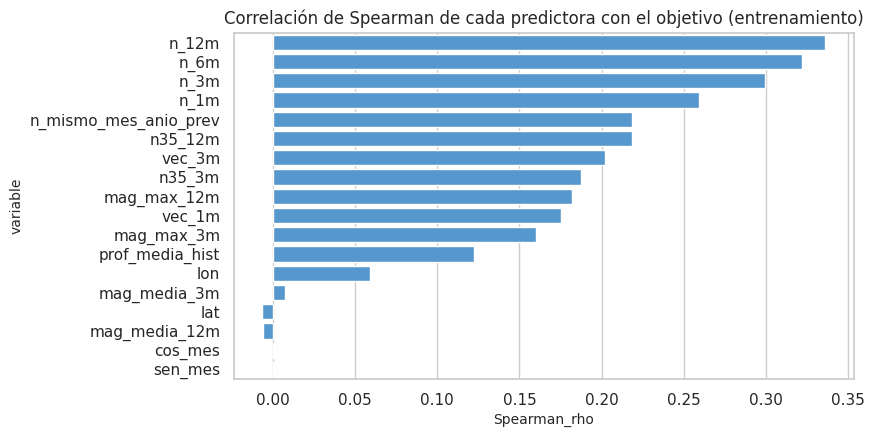

**Interpretación.** Las predictoras más asociadas al conteo del mes siguiente son los **conteos recientes de la propia celda**
(n_12m, n_6m, n_3m, n_1m, ρ entre 0,26 y 0,34). Las variables de
calendario (`sen_mes`, `cos_mes`) casi no se asocian (|ρ| < 0,01).
La sismicidad no tiene estacionalidad apreciable, algo que el capítulo 7 confirma formalmente.

In [7]:
# Relación monótona (Spearman) de cada predictora con el objetivo
rel = []
for c in X.columns:
    x = P[c].to_numpy()
    ok = ~np.isnan(x)
    rho, p = stats.spearmanr(x[ok], y[ok])
    rel.append({"variable": c, "Spearman_rho": rho, "p": p})
rel = pd.DataFrame(rel)
rel["p_FDR"] = eda.fdr_bh(rel.p)
rel = rel.sort_values("Spearman_rho", key=np.abs, ascending=False)
eda.guardar_tabla(rel, "objetivo_spearman.csv")
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=rel, y="variable", x="Spearman_rho", color="#4299e1", ax=ax)
ax.set_title("Correlación de Spearman de cada predictora con el objetivo (entrenamiento)")
eda.guardar_figura(fig, "03_spearman_objetivo.png"); plt.show()
md(f"""**Interpretación.** Las predictoras más asociadas al conteo del mes siguiente son los **conteos recientes de la propia celda**
({', '.join(rel.variable.head(4))}, ρ entre {es(rel.Spearman_rho.head(4).min(), 2)} y {es(rel.Spearman_rho.head(4).max(), 2)}). Las variables de
calendario (`sen_mes`, `cos_mes`) casi no se asocian (|ρ| < {es(rel.loc[rel.variable.isin(['sen_mes', 'cos_mes']), 'Spearman_rho'].abs().max() + 0.005, 2)}).
La sismicidad no tiene estacionalidad apreciable, algo que el capítulo 7 confirma formalmente.""")

## Comportamiento en el tiempo y en el espacio

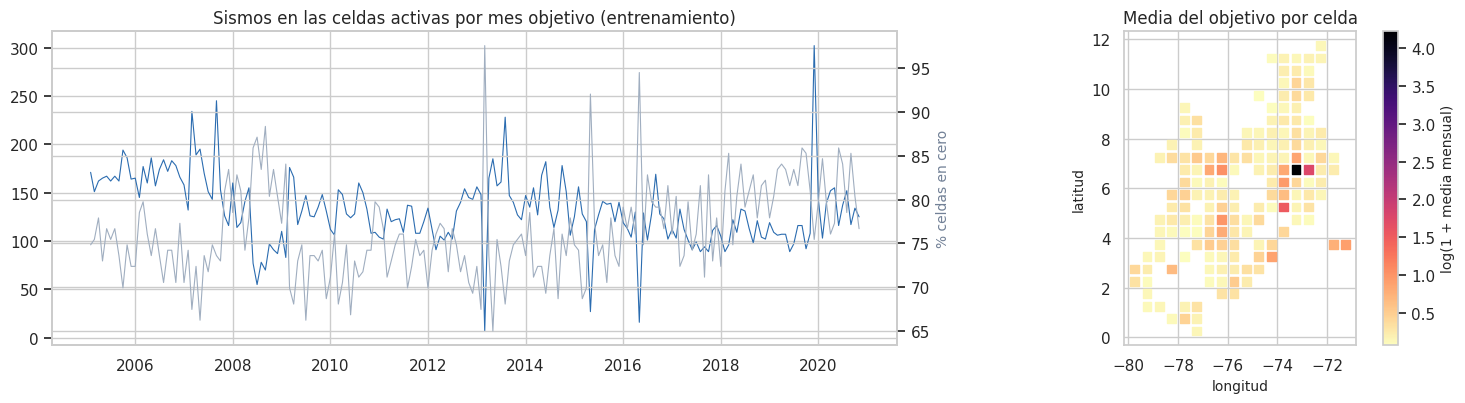

**Interpretación.**
- **En el tiempo.** El total mensual oscila alrededor de 128 sismos (mediana), con picos aislados de
  enjambres. El porcentaje de celdas en cero se mantiene estable (entre 69 % y
  85 % en el 90 % de los meses).
- **En el espacio.** La media por celda varía en **más de tres órdenes de magnitud**: de 0,08 a 67,0 sismos/mes.
  Una sola celda (Bucaramanga) concentra buena parte del total. Esta heterogeneidad explica la sobredispersión global y exige
  que el modelo use la **historia propia de cada celda**.

In [8]:
# Evolución mensual del total de sismos y de la proporción de ceros, y media por celda en el mapa
mensual = P.groupby("fecha_obj").y.agg(["sum", "mean", lambda s: np.mean(s == 0)]).rename(columns={"<lambda_0>": "ceros"})
celda = P.groupby(["celda", "lat", "lon"]).y.mean().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].plot(mensual.index, mensual["sum"], lw=0.8, color="#2b6cb0")
axes[0].set_title("Sismos en las celdas activas por mes objetivo (entrenamiento)")
ax2 = axes[0].twinx(); ax2.plot(mensual.index, mensual["ceros"] * 100, lw=0.8, color="#a0aec0"); ax2.set_ylabel("% celdas en cero", color="#718096")
sc = axes[1].scatter(celda.lon, celda.lat, c=np.log1p(celda.y), s=40, marker="s", cmap="magma_r")
plt.colorbar(sc, ax=axes[1], label="log(1 + media mensual)"); axes[1].set_title("Media del objetivo por celda")
axes[1].set_xlabel("longitud"); axes[1].set_ylabel("latitud"); axes[1].set_aspect("equal")
plt.tight_layout(); eda.guardar_figura(fig, "03_objetivo_tiempo_espacio.png"); plt.show()
md(f"""**Interpretación.**
- **En el tiempo.** El total mensual oscila alrededor de {es(mensual['sum'].median(), 0)} sismos (mediana), con picos aislados de
  enjambres. El porcentaje de celdas en cero se mantiene estable (entre {es(mensual.ceros.quantile(0.05), 0, pct=True)} y
  {es(mensual.ceros.quantile(0.95), 0, pct=True)} en el 90 % de los meses).
- **En el espacio.** La media por celda varía en **más de tres órdenes de magnitud**: de {es(celda.y.min(), 2)} a {es(celda.y.max(), 1)} sismos/mes.
  Una sola celda (Bucaramanga) concentra buena parte del total. Esta heterogeneidad explica la sobredispersión global y exige
  que el modelo use la **historia propia de cada celda**.""")

## Implicaciones para la métrica y la validación

1. **Transformación del objetivo.**
   - Con 76 % de ceros y cola de ley de potencia, Box-Cox no es aplicable (requiere y > 0).
   - Se modela **log(1 + y)**: reduce la asimetría de 13,2 a 3,9 (tabla de arriba) y convierte el
     error relativo en error absoluto. La asimetría restante se debe a la masa en cero, que ninguna
     transformación monótona elimina.
   - Los modelos se entrenan sobre log1p y se evalúan en la escala original con `expm1`.
2. **Métrica principal: RMSLE.** Coincide con la pérdida en escala log y no se deja dominar por los
   enjambres, a diferencia del RMSE. El MAPE no se puede usar como métrica principal porque se
   indefine con ceros.
3. **Validación.**
   - La dependencia temporal (enjambres que duran varios meses) obliga a una **partición
     cronológica con gap**.
   - La heterogeneidad entre celdas obliga a reportar también un esquema **por bloques espaciales**,
     que mide cuánto empeora el modelo en zonas que no vio (capítulo 11).
   - La incertidumbre se estima **remuestreando meses**.
4. **Modelos de conteo.** La sobredispersión y el exceso de ceros dentro de cada celda justifican,
   en el Entregable 2, probar pérdidas de Poisson y modelos binomiales negativos inflados en ceros
   (ZINB).